In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("../data/raw/credit_risk_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


In [5]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [6]:
df.describe(include="object")

C:\Users\ikhtiar\AppData\Local\Temp\ipykernel_49540\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
count,32581,32581,32581,32581
unique,4,6,7,2
top,RENT,EDUCATION,A,N
freq,16446,6453,10777,26836


In [7]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)

,missing_count,missing_percentage
loan_int_rate,3116,9.563856
person_emp_length,895,2.747000
person_income,0,0.000000
person_age,0,0.000000
person_home_ownership,0,0.000000
loan_intent,0,0.000000
loan_grade,0,0.000000
loan_amnt,0,0.000000
loan_status,0,0.000000
loan_percent_income,0,0.000000


In [10]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 165


In [11]:
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

In [12]:
df["loan_status"].value_counts(normalize=True) * 100

loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64

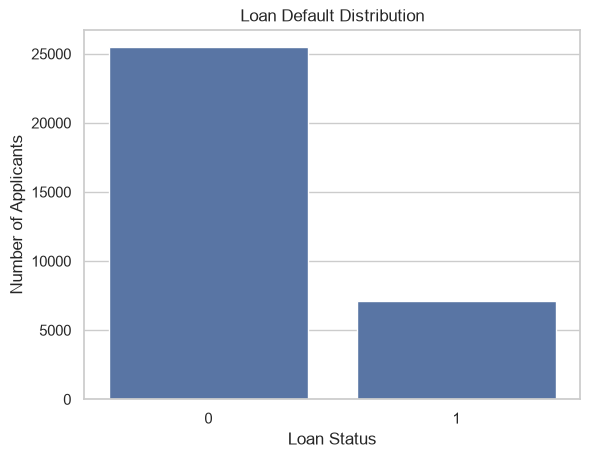

In [13]:
sns.countplot(
    data=df,
    x="loan_status"
)

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.show()

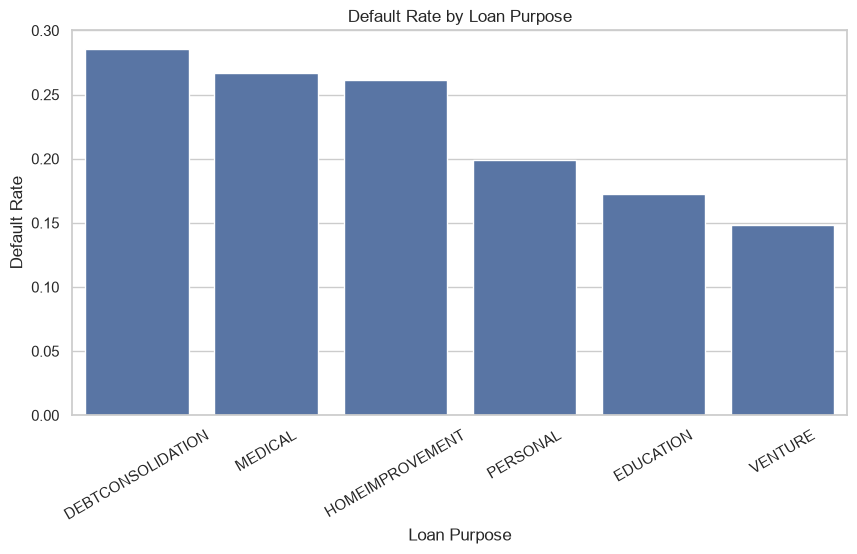

In [14]:
default_by_purpose = (
    df.groupby("loan_intent")["loan_status"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=default_by_purpose.index,
    y=default_by_purpose.values
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate")

plt.xticks(rotation=30)
plt.show()

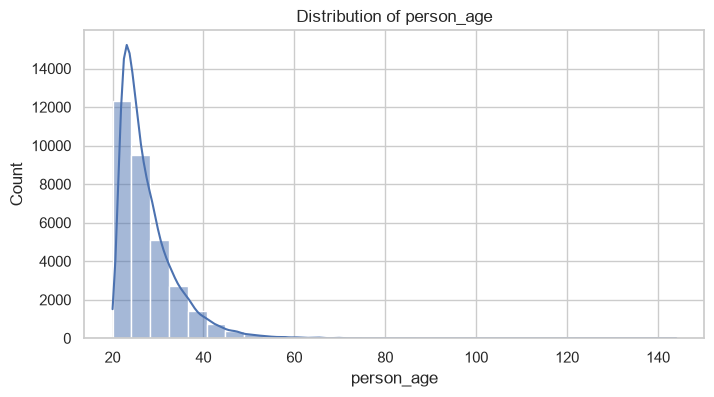

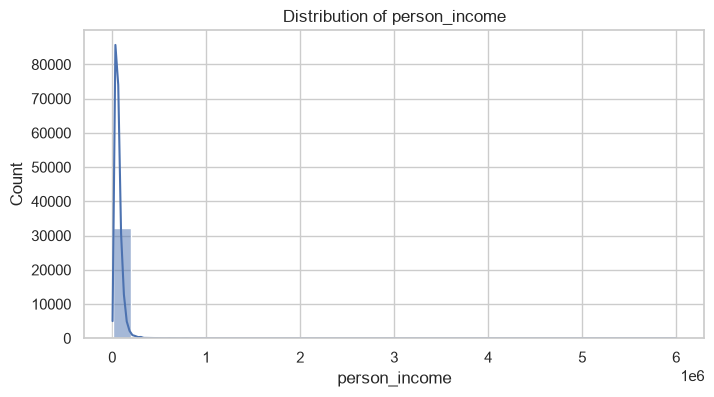

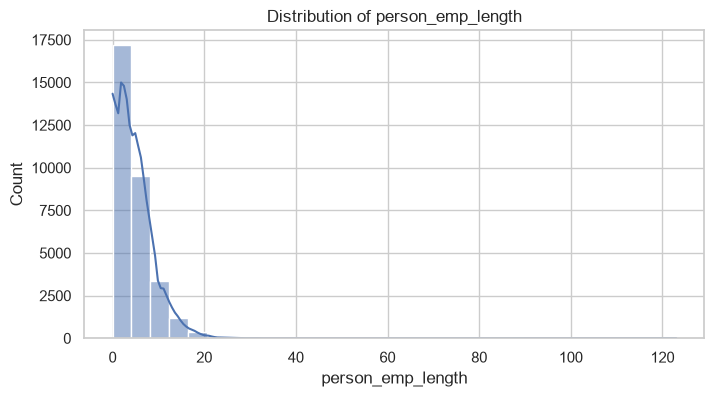

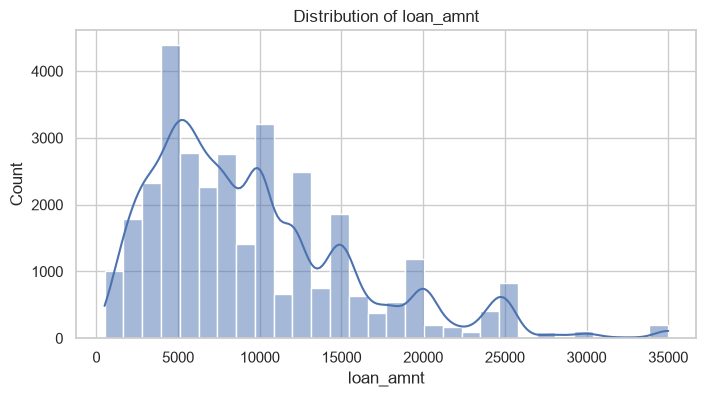

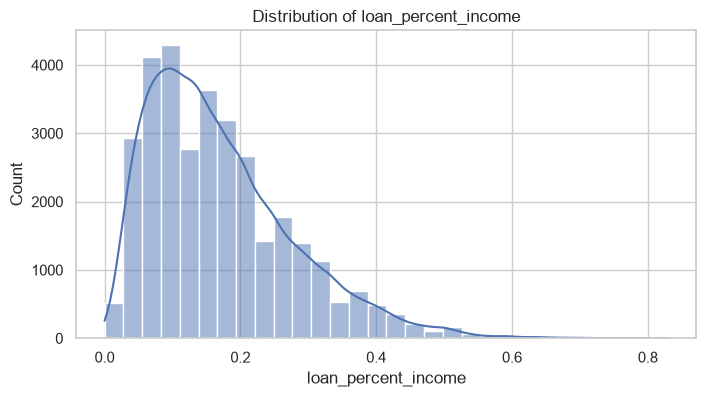

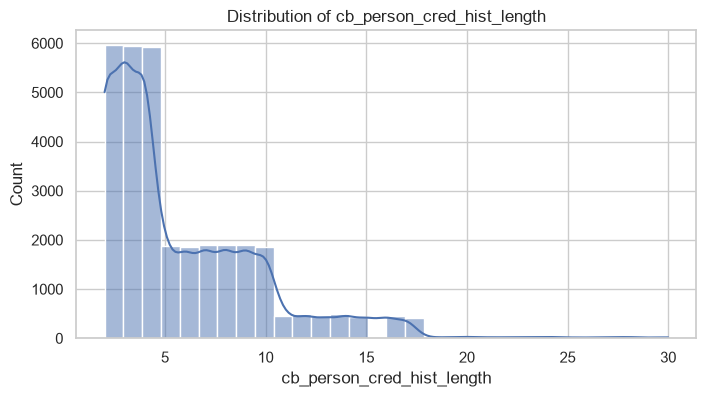

In [15]:
numerical_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

for feature in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {feature}")

    plt.show()

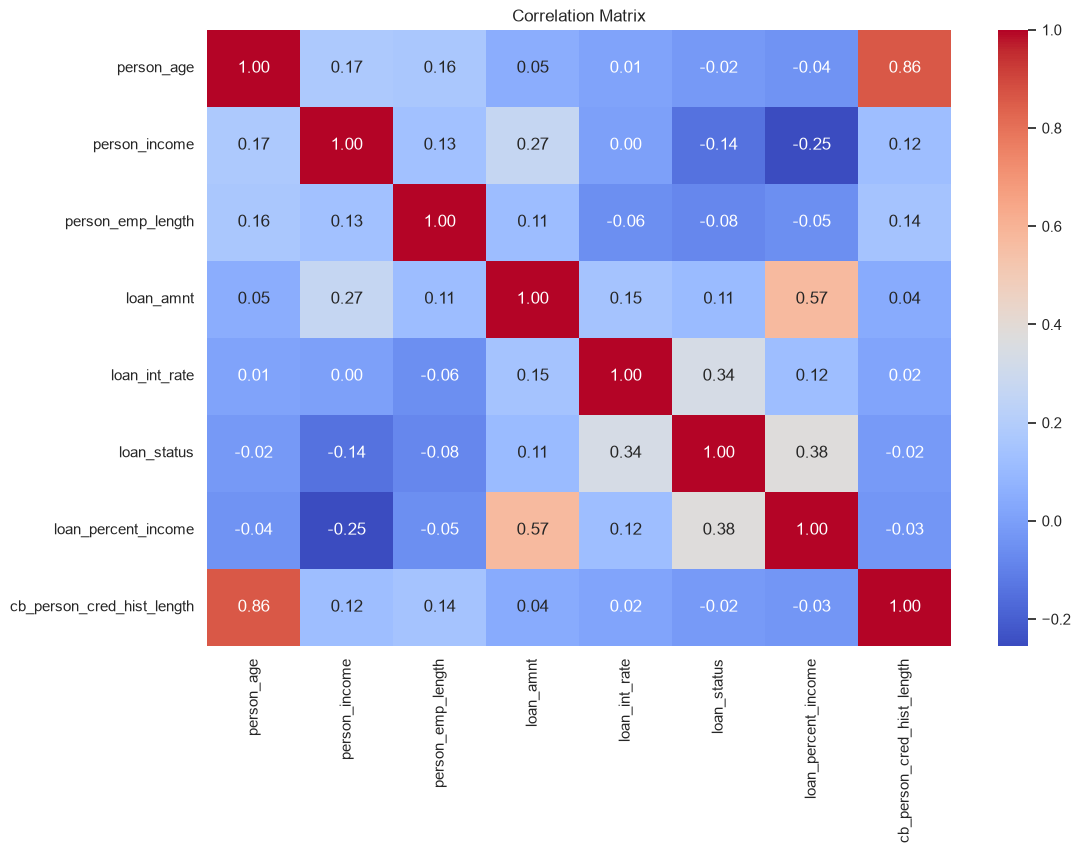

In [16]:
correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [17]:
# Age above 100
print("Age above 100:")
display(df[df["person_age"] > 100])

# Employment length above 50
print("Employment length above 50:")
display(df[df["person_emp_length"] > 50])

# Income above 1 million
print("Income above 1 million:")
display(df[df["person_income"] > 1_000_000])

# Compare extreme values using quantiles
display(
    df[
        [
            "person_age",
            "person_income",
            "person_emp_length",
            "loan_amnt",
            "loan_int_rate"
        ]
    ].quantile([0.90, 0.95, 0.99, 0.995, 0.999])
)

Age above 100:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


Employment length above 50:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


Income above 1 million:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
17833,32,1200000,MORTGAGE,1.0,VENTURE,A,12000,7.51,0,0.01,N,8
29119,36,1200000,OWN,16.0,MEDICAL,A,10000,6.54,0,0.01,N,11
29120,40,1200000,MORTGAGE,1.0,MEDICAL,A,10000,NaN,0,0.01,N,16
30049,42,2039784,RENT,0.0,VENTURE,C,8450,12.29,0,0.00,Y,15
31922,47,1362000,MORTGAGE,9.0,VENTURE,A,6600,7.74,0,0.00,N,17
31924,44,1440000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,6400,7.40,0,0.00,N,15
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25
32497,63,1782000,RENT,13.0,EDUCATION,C,12025,14.27,0,0.01,N,30
32546,60,1900000,MORTGAGE,5.0,PERSONAL,A,1500,NaN,0,0.00,N,21


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate
0.900,36.0,110004.0,10.0,19000.0,15.298
0.950,40.0,138000.0,13.0,24000.0,16.320
0.990,50.0,225200.0,18.0,29800.0,18.620
0.995,54.0,300000.0,19.0,35000.0,19.290
0.999,66.0,648000.0,25.0,35000.0,20.890


In [18]:
categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

for feature in categorical_features:

    result = (
        df.groupby(feature)["loan_status"]
        .agg(
            total_records="count",
            defaults="sum",
            default_rate="mean"
        )
        .sort_values("default_rate", ascending=False)
    )

    result["default_rate"] *= 100

    print(f"\nDefault rate by {feature}")
    display(result)


Default rate by person_home_ownership


,total_records,defaults,default_rate
person_home_ownership,,,
RENT,16446,5192,31.569987
OTHER,107,33,30.841121
MORTGAGE,13444,1690,12.570663
OWN,2584,193,7.469040



Default rate by loan_intent


,total_records,defaults,default_rate
loan_intent,,,
DEBTCONSOLIDATION,5212,1490,28.587874
MEDICAL,6071,1621,26.700708
HOMEIMPROVEMENT,3605,941,26.102635
PERSONAL,5521,1098,19.887702
EDUCATION,6453,1111,17.216798
VENTURE,5719,847,14.810282



Default rate by loan_grade


,total_records,defaults,default_rate
loan_grade,,,
G,64,63,98.437500
F,241,170,70.539419
E,964,621,64.419087
D,3626,2141,59.045780
C,6458,1339,20.733973
B,10451,1701,16.275954
A,10777,1073,9.956389



Default rate by cb_person_default_on_file


,total_records,defaults,default_rate
cb_person_default_on_file,,,
Y,5745,2172,37.806789
N,26836,4936,18.393203


In [19]:
missing_analysis = (
    df.assign(
        interest_rate_missing=df["loan_int_rate"].isna(),
        employment_length_missing=df["person_emp_length"].isna()
    )
    .groupby("loan_status")[
        ["interest_rate_missing", "employment_length_missing"]
    ]
    .mean() * 100
)

display(missing_analysis)

,interest_rate_missing,employment_length_missing
loan_status,,
0,9.704393,2.406470
1,9.060214,3.967361


In [20]:
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in exact duplicates:", len(duplicates))

display(
    duplicates.sort_values(
        by=list(df.columns)
    ).head(20)
)

Rows involved in exact duplicates: 330


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
17758,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
2498,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
17601,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
1778,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
17642,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3


In [21]:
df_clean = df.copy()

In [25]:
invalid_age_count = (df_clean["person_age"] > 100).sum()
print(invalid_age_count)

5


In [26]:
df_clean = df_clean[df_clean["person_age"] <= 100].copy()

In [27]:
df_clean.loc[
    df_clean["person_emp_length"] > 50,
    "person_emp_length"
] = float("nan")

In [28]:
# 3. Remove exact duplicate records
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

In [29]:
# 4. Display cleaning summary
print("Data cleaning summary")
print("---------------------")

print(f"Original records: {len(df)}")
print(f"Invalid age records removed: {invalid_age_count}")
print(f"Duplicate records removed: {duplicates_before}")
print(f"Final records: {len(df_clean)}")

print("\nRemaining missing values:")
display(df_clean.isnull().sum())

print("\nUpdated target distribution:")
display(df_clean["loan_status"].value_counts(normalize=True) * 100)

Data cleaning summary
---------------------
Original records: 32581
Invalid age records removed: 5
Duplicate records removed: 165
Final records: 32411

Remaining missing values:


person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              889
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3094
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


Updated target distribution:


loan_status
0    78.127796
1    21.872204
Name: proportion, dtype: float64

In [30]:
numeric_features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

categorical_features = [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file",
]

feature_columns = numeric_features + categorical_features

X = df_clean[feature_columns].copy()
y = df_clean["loan_status"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (32411, 9)
Target shape: (32411,)


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (25928, 9)
Testing features: (6483, 9)

Training target distribution:
loan_status
0    0.781279
1    0.218721
Name: proportion, dtype: float64

Testing target distribution:
loan_status
0    0.781274
1    0.218726
Name: proportion, dtype: float64


In [54]:
import os

print("Current directory:", os.getcwd())
print("Files and folders:", os.listdir())

Current directory: c:\Users\ikhtiar\Desktop\credit-risk\notebooks
Files and folders: ['01_eda.ipynb', 'credit_risk_training.ipynb']


In [55]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\ikhtiar\Desktop\credit-risk")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [39]:
from src.preprocessing.pipeline import build_preprocessor

preprocessor = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
)

# Learn preprocessing parameters from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (25928, 18)
Processed testing shape: (6483, 18)


In [41]:
import mlflow
import mlflow.sklearn

from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\ikhtiar\Desktop\credit-risk")

mlflow.set_tracking_uri(
    f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}"
)

experiment = mlflow.set_experiment(
    "credit-risk-default-prediction"
)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Experiment name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)

MLflow tracking URI: sqlite:///C:/Users/ikhtiar/Desktop/credit-risk/mlflow.db
Experiment name: credit-risk-default-prediction
Experiment ID: 1


In [42]:
print(mlflow.get_tracking_uri())

print(
    mlflow.search_experiments()
)

sqlite:///C:/Users/ikhtiar/Desktop/credit-risk/mlflow.db
[<Experiment: artifact_location='file:C:/Users/ikhtiar/Desktop/credit-risk/mlruns/1', creation_time=1793761354438, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793761354438, lifecycle_stage='active', name='credit-risk-default-prediction', tags={}, trace_location=None, workspace='default'>, <Experiment: artifact_location='mlflow-artifacts:/0', creation_time=1793761041499, effective_trace_archival_retention=None, experiment_id='0', last_update_time=1793761041499, lifecycle_stage='active', name='Default', tags={}, trace_location=None, workspace='default'>]


In [44]:

import mlflow
import mlflow.sklearn

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

# ==================================================
# 1. CONFIGURE DATA TYPES
# ==================================================

X_train = X_train.copy()
X_test = X_test.copy()

for column in numeric_features:
    X_train[column] = X_train[column].astype("float64")
    X_test[column] = X_test[column].astype("float64")


# ==================================================
# 2. CONFIGURE MLFLOW
# ==================================================

mlflow.set_tracking_uri(
    "sqlite:///C:/Users/ikhtiar/Desktop/credit-risk/mlflow.db"
)

mlflow.set_experiment("credit-risk-default-prediction")

# Enable sklearn autologging
mlflow.sklearn.autolog(
    log_models=False,
    log_input_examples=False,
    log_model_signatures=False,
    log_datasets=True,
)


# ==================================================
# 3. BUILD MODEL PIPELINE
# ==================================================

model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42,
            ),
        ),
    ]
)


# ==================================================
# 4. START MLFLOW RUN
# ==================================================

with mlflow.start_run(
    run_name="logistic-regression-baseline-v2"
):

    # Experiment metadata
    mlflow.set_tags({
        "model_stage": "baseline",
        "problem_type": "binary_classification",
        "prediction_target": "loan_status",
        "dataset": "OpenML Credit Risk Dataset",
        "feature_strategy": "application_stage_features",
    })

    # Explicit parameters
    mlflow.log_params({
        "test_size": 0.20,
        "random_state": 42,
        "training_samples": len(X_train),
        "testing_samples": len(X_test),
        "numeric_features": len(numeric_features),
        "categorical_features": len(categorical_features),
        "decision_threshold": 0.5,
        "max_iter": 1000,
        "class_weight": "None",
    })


    # ==================================================
    # 5. TRAIN MODEL
    # ==================================================

    model_pipeline.fit(X_train, y_train)

    print("Model training completed!")


    # ==================================================
    # 6. GENERATE PREDICTIONS
    # ==================================================

    y_pred = model_pipeline.predict(X_test)

    y_proba = model_pipeline.predict_proba(X_test)[:, 1]


    # ==================================================
    # 7. EVALUATE MODEL
    # ==================================================

    metrics = {
        "test_accuracy": accuracy_score(y_test, y_pred),
        "test_precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "test_recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "test_f1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "test_roc_auc": roc_auc_score(y_test, y_proba),
        "test_pr_auc": average_precision_score(y_test, y_proba),
    }

    # Log evaluation metrics
    mlflow.log_metrics(metrics)


    # ==================================================
    # 8. LOG TRAINED MODEL
    # ==================================================

    mlflow.sklearn.log_model(
        sk_model=model_pipeline,
        name="logistic-regression-model",
        input_example=X_train.head(3),
        serialization_format="cloudpickle",
    )


    # ==================================================
    # 9. LOG EVALUATION ARTIFACTS
    # ==================================================

    cm = confusion_matrix(y_test, y_pred)

    report = classification_report(
        y_test,
        y_pred,
        zero_division=0,
    )

    mlflow.log_text(
        str(cm),
        "evaluation/confusion_matrix.txt",
    )

    mlflow.log_text(
        report,
        "evaluation/classification_report.txt",
    )


    # ==================================================
    # 10. DISPLAY RESULTS
    # ==================================================

    print("\n========== MODEL EVALUATION ==========")

    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(report)

    print(
        "\nMLflow Run ID:",
        mlflow.active_run().info.run_id,
    )

print("\nExperiment completed!")


c:\Users\ikhtiar\Desktop\credit-risk\.venv\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


Model training completed!


2026/11/04 10:00:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\ikhtiar\Desktop\credit-risk\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing v


========== MODEL EVALUATION ==========
test_accuracy: 0.8357
test_precision: 0.7289
test_recall: 0.3963
test_f1: 0.5135
test_roc_auc: 0.7999
test_pr_auc: 0.6201

Confusion Matrix:
[[4856  209]
 [ 856  562]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      5065
           1       0.73      0.40      0.51      1418

    accuracy                           0.84      6483
   macro avg       0.79      0.68      0.71      6483
weighted avg       0.82      0.84      0.82      6483


MLflow Run ID: c43f473ee5ed4a58a812e0eca3cb28d9

Experiment completed!


In [45]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train,
)

print("Training:", X_fit.shape)
print("Validation:", X_val.shape)

Training: (20742, 9)
Validation: (5186, 9)


In [46]:
from sklearn.base import clone

validation_model = clone(model_pipeline)

validation_model.fit(X_fit, y_fit)

# Get default probabilities
y_val_proba = validation_model.predict_proba(X_val)[:, 1]

print("Validation model trained!")

2026/11/04 10:04:45 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '35349180a17d4b1089979c21e7e53ef5', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
c:\Users\ikhtiar\Desktop\credit-risk\.venv\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


Validation model trained!


In [47]:
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:

    y_val_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_val_pred,
    ).ravel()

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    })

threshold_results = pd.DataFrame(results)

print(
    threshold_results.round(4).to_string(index=False)
)

 threshold  precision  recall  f1_score  false_positives  false_negatives  true_positives
      0.20     0.4104  0.7108    0.5203             1158              328             806
      0.25     0.4710  0.6596    0.5496              840              386             748
      0.30     0.5144  0.5996    0.5537              642              454             680
      0.35     0.5670  0.5450    0.5558              472              516             618
      0.40     0.6360  0.5053    0.5631              328              561             573
      0.45     0.6890  0.4436    0.5397              227              631             503
      0.50     0.7194  0.3889    0.5049              172              693             441


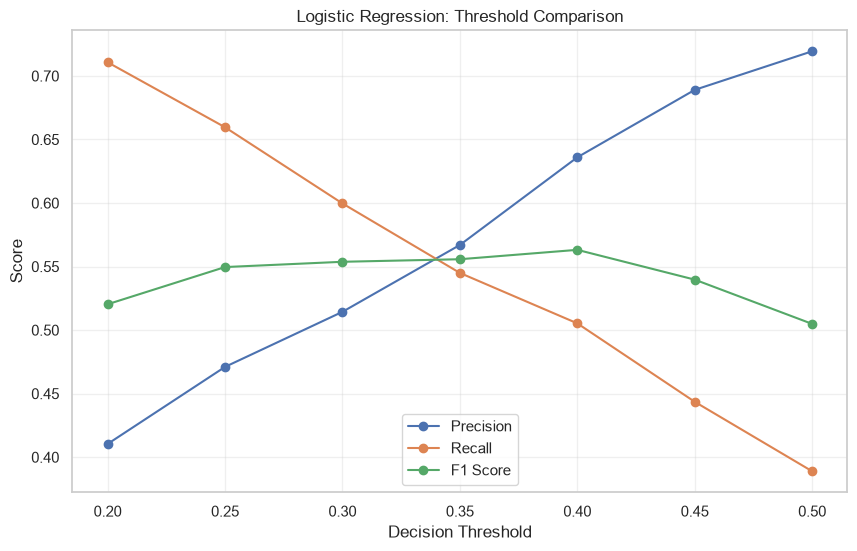

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision",
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall",
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1_score"],
    marker="o",
    label="F1 Score",
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression: Threshold Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [50]:
with mlflow.start_run(
    run_name="logistic-regression-threshold-analysis"
):

    mlflow.set_tag("experiment_type", "threshold_analysis")

    for _, row in threshold_results.iterrows():

        threshold = row["threshold"]

        mlflow.log_metrics({
            f"precision_at_{threshold:.2f}": row["precision"],
            f"recall_at_{threshold:.2f}": row["recall"],
            f"f1_at_{threshold:.2f}": row["f1_score"],
            f"false_negatives_at_{threshold:.2f}": row["false_negatives"],
            f"false_positives_at_{threshold:.2f}": row["false_positives"],
        })

print("Threshold experiment logged!")

Threshold experiment logged!


In [51]:

from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
)

# Selected using validation data
selected_threshold = 0.40

# Create a fresh model
final_lr_model = clone(model_pipeline)

# Train on the complete training dataset
final_lr_model.fit(X_train, y_train)

# Get default probabilities on untouched test data
y_test_proba = final_lr_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred = (
    y_test_proba >= selected_threshold
).astype(int)

# Evaluate
final_metrics = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred),
    "recall": recall_score(y_test, y_test_pred),
    "f1_score": f1_score(y_test, y_test_pred),
    "roc_auc": roc_auc_score(y_test, y_test_proba),
    "pr_auc": average_precision_score(y_test, y_test_proba),
}

print("Threshold:", selected_threshold)

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


2026/11/04 10:07:40 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '17c174f98dc44d96a6e9429ad0a28ebe', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
c:\Users\ikhtiar\Desktop\credit-risk\.venv\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


Threshold: 0.4
accuracy: 0.8263
precision: 0.6311
recall: 0.4958
f1_score: 0.5553
roc_auc: 0.7999
pr_auc: 0.6201

Confusion Matrix:
[[4654  411]
 [ 715  703]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.92      0.89      5065
           1       0.63      0.50      0.56      1418

    accuracy                           0.83      6483
   macro avg       0.75      0.71      0.72      6483
weighted avg       0.82      0.83      0.82      6483



In [52]:
with mlflow.start_run(
    run_name="logistic-regression-final-threshold-040"
):

    mlflow.set_tags({
        "model_type": "LogisticRegression",
        "evaluation_stage": "held_out_test",
        "threshold_selection": "validation_set",
    })

    mlflow.log_param(
        "selected_threshold",
        selected_threshold,
    )

    mlflow.log_metrics({
        f"test_{metric}": value
        for metric, value in final_metrics.items()
    })

    mlflow.log_text(
        str(confusion_matrix(y_test, y_test_pred)),
        "evaluation/confusion_matrix_threshold_040.txt",
    )

    mlflow.log_text(
        classification_report(y_test, y_test_pred),
        "evaluation/classification_report_threshold_040.txt",
    )

print("Final threshold evaluation logged!")

Final threshold evaluation logged!


In [57]:
import importlib
import src.preprocessing.pipeline as pipeline

importlib.reload(pipeline)

from src.preprocessing.pipeline import build_tree_preprocessor

In [58]:
import src.preprocessing.pipeline as pipeline

print(pipeline.__file__)

C:\Users\ikhtiar\Desktop\credit-risk\src\preprocessing\pipeline.py


In [59]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from src.preprocessing.pipeline import build_tree_preprocessor

tree_preprocessor = build_tree_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
)

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

In [60]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train,
)

print("Fit data:", X_fit.shape)
print("Validation data:", X_val.shape)

Fit data: (20742, 9)
Validation data: (5186, 9)


In [61]:
import time

start_time = time.time()

rf_pipeline.fit(X_fit, y_fit)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds")

2026/11/04 10:16:31 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '9a9c1335389c407a9d6181c2ba04d4bd', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
c:\Users\ikhtiar\Desktop\credit-risk\.venv\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


Training completed in 2.67 seconds


In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

y_val_proba = rf_pipeline.predict_proba(X_val)[:, 1]

y_val_pred = (y_val_proba >= 0.50).astype(int)

print("Validation Results — Threshold 0.50")
print("-" * 40)

print(f"Accuracy:  {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred):.4f}")
print(f"F1-score:  {f1_score(y_val, y_val_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, y_val_proba):.4f}")

Validation Results — Threshold 0.50
----------------------------------------
Accuracy:  0.8777
Precision: 0.8687
Recall:    0.5194
F1-score:  0.6501
ROC-AUC:   0.8677
PR-AUC:    0.7666


In [63]:
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    y_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "f1_score": f1_score(y_val, y_pred),
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    })

rf_threshold_results = pd.DataFrame(threshold_results)

rf_threshold_results.round(4)

,threshold,precision,recall,f1_score,false_positives,false_negatives,true_positives
0,0.20,0.5108,0.7698,0.6141,836,261,873
1,0.25,0.5865,0.6993,0.6380,559,341,793
2,0.30,0.6559,0.6623,0.6591,394,383,751
3,0.35,0.7074,0.6182,0.6598,290,433,701
4,0.40,0.7604,0.5794,0.6577,207,477,657
5,0.45,0.8199,0.5459,0.6554,136,515,619
6,0.50,0.8687,0.5194,0.6501,89,545,589


In [64]:
best_rf_row = rf_threshold_results.loc[
    rf_threshold_results["f1_score"].idxmax()
]

selected_rf_threshold = float(best_rf_row["threshold"])

print("Selected threshold:", selected_rf_threshold)
print(best_rf_row)

Selected threshold: 0.35
threshold            0.350000
precision            0.707366
recall               0.618166
f1_score             0.659765
false_positives    290.000000
false_negatives    433.000000
true_positives     701.000000
Name: 3, dtype: float64


In [65]:
import mlflow

with mlflow.start_run(run_name="random-forest-validation"):

    mlflow.set_tags({
        "model_type": "RandomForest",
        "evaluation_stage": "validation",
        "experiment_type": "baseline_threshold_analysis",
    })

    mlflow.log_params({
        "n_estimators": 300,
        "random_state": 42,
        "n_jobs": -1,
    })

    mlflow.log_metric("training_time_seconds", training_time)

    for _, row in rf_threshold_results.iterrows():

        threshold = row["threshold"]

        mlflow.log_metrics({
            f"precision_at_{threshold:.2f}": row["precision"],
            f"recall_at_{threshold:.2f}": row["recall"],
            f"f1_at_{threshold:.2f}": row["f1_score"],
            f"false_positives_at_{threshold:.2f}": row["false_positives"],
            f"false_negatives_at_{threshold:.2f}": row["false_negatives"],
        })

    mlflow.log_text(
        rf_threshold_results.to_csv(index=False),
        "evaluation/threshold_results.csv",
    )

print("Random Forest validation experiment logged.")

Random Forest validation experiment logged.


In [66]:
from sklearn.base import clone

final_rf_model = clone(rf_pipeline)

start_time = time.time()

final_rf_model.fit(X_train, y_train)

final_rf_training_time = time.time() - start_time

print(
    f"Final Random Forest training time: "
    f"{final_rf_training_time:.2f} seconds"
)

2026/11/04 10:17:49 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '362b92dbf7d747e2becfa6e8f4850eac', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
c:\Users\ikhtiar\Desktop\credit-risk\.venv\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


Final Random Forest training time: 3.02 seconds


In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

y_test_proba_rf = final_rf_model.predict_proba(X_test)[:, 1]

y_test_pred_rf = (
    y_test_proba_rf >= selected_rf_threshold
).astype(int)

rf_test_metrics = {
    "accuracy": accuracy_score(y_test, y_test_pred_rf),
    "precision": precision_score(y_test, y_test_pred_rf),
    "recall": recall_score(y_test, y_test_pred_rf),
    "f1_score": f1_score(y_test, y_test_pred_rf),
    "roc_auc": roc_auc_score(y_test, y_test_proba_rf),
    "pr_auc": average_precision_score(y_test, y_test_proba_rf),
}

print("Random Forest — Final Test Results")
print("=" * 45)
print("Selected threshold:", selected_rf_threshold)

for metric, value in rf_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf))

Random Forest — Final Test Results
Selected threshold: 0.35
accuracy: 0.8658
precision: 0.7217
recall: 0.6291
f1_score: 0.6722
roc_auc: 0.8715
pr_auc: 0.7777

Confusion Matrix:
[[4721  344]
 [ 526  892]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.93      0.92      5065
           1       0.72      0.63      0.67      1418

    accuracy                           0.87      6483
   macro avg       0.81      0.78      0.79      6483
weighted avg       0.86      0.87      0.86      6483



In [68]:
with mlflow.start_run(run_name="random-forest-final-test"):

    mlflow.set_tags({
        "model_type": "RandomForest",
        "evaluation_stage": "held_out_test",
        "threshold_selection": "validation_set",
    })

    mlflow.log_params({
        "n_estimators": 300,
        "random_state": 42,
        "n_jobs": -1,
        "selected_threshold": selected_rf_threshold,
    })

    mlflow.log_metrics({
        f"test_{metric}": value
        for metric, value in rf_test_metrics.items()
    })

    mlflow.log_metric(
        "training_time_seconds",
        final_rf_training_time,
    )

    mlflow.log_text(
        str(confusion_matrix(y_test, y_test_pred_rf)),
        "evaluation/confusion_matrix.txt",
    )

    mlflow.log_text(
        classification_report(y_test, y_test_pred_rf),
        "evaluation/classification_report.txt",
    )

    mlflow.sklearn.log_model(
        sk_model=final_rf_model,
        name="random-forest-model",
        input_example=X_train.head(3),
        serialization_format="cloudpickle",
    )

print("Final Random Forest experiment logged in MLflow.")

2026/11/04 10:18:13 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\ikhtiar\Desktop\credit-risk\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing v

Final Random Forest experiment logged in MLflow.


In [69]:
import pandas as pd

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    estimator=rf_pipeline,
    X=X_val,
    y=y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std,
})

feature_importance = feature_importance.sort_values(
    by="importance_mean",
    ascending=False,
)

feature_importance

,feature,importance_mean,importance_std
4,loan_percent_income,0.273413,0.008447
6,person_home_ownership,0.218325,0.008842
1,person_income,0.125028,0.003843
7,loan_intent,0.083517,0.002825
8,cb_person_default_on_file,0.040746,0.004382
3,loan_amnt,0.020153,0.003253
0,person_age,0.015805,0.003204
2,person_emp_length,0.011441,0.001852
5,cb_person_cred_hist_length,0.000309,0.002507


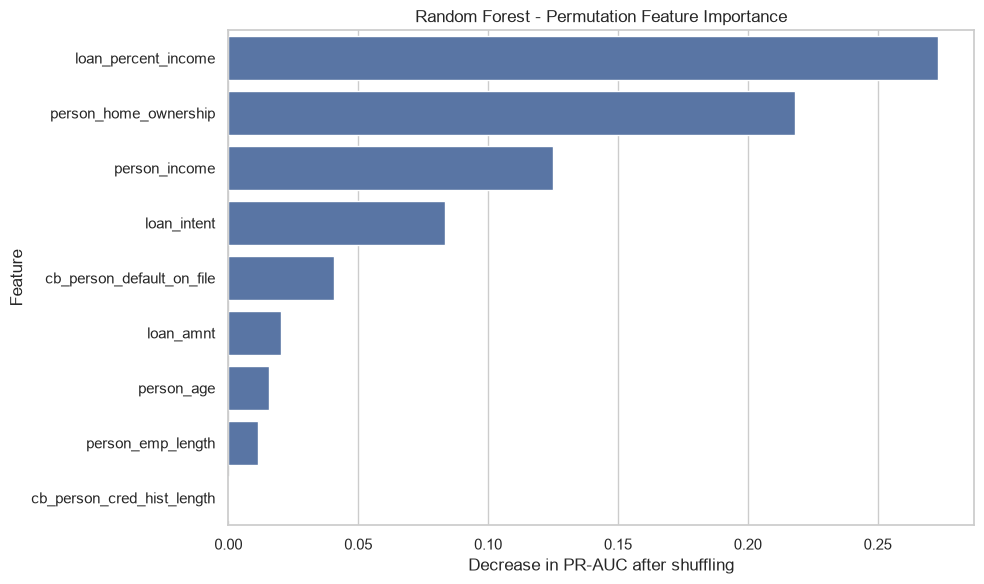

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="importance_mean",
    y="feature",
)

plt.title("Random Forest - Permutation Feature Importance")
plt.xlabel("Decrease in PR-AUC after shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Random Forest hyperparameter tuning



Tune on `X_fit`/`y_fit` only, then use `X_val`/`y_val` for threshold selection. The held-out test section remains below and is not part of this tuning run.

In [48]:
import time

from scipy.stats import randint

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold



# Avoid nested parallelism: the search owns parallel execution.

rf_pipeline.set_params(classifier__n_jobs=1)

mlflow.sklearn.autolog(disable=True)



param_distributions = {

    "classifier__n_estimators": randint(200, 601),

    "classifier__max_depth": [None, 10, 15, 20, 30],

    "classifier__min_samples_split": randint(2, 21),

    "classifier__min_samples_leaf": randint(1, 11),

    "classifier__max_features": ["sqrt", "log2", 0.5, None],

    "classifier__class_weight": [None, "balanced", "balanced_subsample"],

}



cv_strategy = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42,

)



random_search = RandomizedSearchCV(

    estimator=rf_pipeline,

    param_distributions=param_distributions,

    n_iter=30,

    scoring="average_precision",

    cv=cv_strategy,

    verbose=2,

    random_state=42,

    n_jobs=-1,

    refit=True,

    return_train_score=True,

    error_score="raise",

)


In [49]:
start_time = time.time()

random_search.fit(X_fit, y_fit)

search_time = time.time() - start_time



print(f"Search completed in {search_time / 60:.2f} minutes")

print("Best cross-validation PR-AUC:", random_search.best_score_)

print("\nBest parameters:")

for parameter, value in random_search.best_params_.items():

    print(f"{parameter}: {value}")


Fitting 5 folds for each of 30 candidates, totalling 150 fits


Search completed in 2.56 minutes
Best cross-validation PR-AUC: 0.7913651227611738

Best parameters:
classifier__class_weight: None
classifier__max_depth: 20
classifier__max_features: None
classifier__min_samples_leaf: 8
classifier__min_samples_split: 12
classifier__n_estimators: 280


In [50]:
cv_results = pd.DataFrame(random_search.cv_results_).sort_values(

    by="mean_test_score",

    ascending=False,

)



cv_results[[

    "rank_test_score",

    "mean_train_score",

    "mean_test_score",

    "std_test_score",

    "params",

]].head(10)


,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
16,1,0.923773,0.791365,0.008433,"{'classifier__class_weight': None, 'classifier..."
18,2,0.946507,0.790975,0.009415,"{'classifier__class_weight': 'balanced', 'clas..."
19,3,0.946102,0.790655,0.009087,"{'classifier__class_weight': 'balanced', 'clas..."
4,4,0.923665,0.790294,0.009415,"{'classifier__class_weight': 'balanced', 'clas..."
10,5,0.993698,0.789962,0.010365,"{'classifier__class_weight': 'balanced', 'clas..."
14,6,0.914084,0.789787,0.009498,"{'classifier__class_weight': 'balanced', 'clas..."
28,7,0.892963,0.788684,0.009295,"{'classifier__class_weight': 'balanced', 'clas..."
23,8,0.896632,0.785985,0.010557,"{'classifier__class_weight': None, 'classifier..."
26,9,0.928240,0.785085,0.012232,{'classifier__class_weight': 'balanced_subsamp...
20,10,0.980205,0.784482,0.012265,"{'classifier__class_weight': 'balanced', 'clas..."


In [51]:
with mlflow.start_run(run_name="random-forest-hyperparameter-search"):

    mlflow.set_tags({

        "model_type": "RandomForest",

        "experiment_type": "hyperparameter_tuning",

        "optimization_metric": "average_precision",

    })

    mlflow.log_params({

        "n_iter": 30,

        "cv_folds": 5,

        "scoring": "average_precision",

        "random_state": 42,

    })

    mlflow.log_metric("best_cv_pr_auc", random_search.best_score_)

    mlflow.log_metric("search_time_minutes", search_time / 60)

    for parameter, value in random_search.best_params_.items():

        mlflow.log_param(f"best_{parameter.replace('classifier__', '')}", value)

    mlflow.log_text(

        cv_results.head(10).to_csv(index=False),

        "tuning/top_10_cv_results.csv",

    )



print("Tuning experiment logged in MLflow.")


Tuning experiment logged in MLflow.


In [52]:
best_rf_model = random_search.best_estimator_

y_val_proba_tuned = best_rf_model.predict_proba(X_val)[:, 1]



tuned_threshold_results = []

for threshold in thresholds:

    y_pred = (y_val_proba_tuned >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()

    tuned_threshold_results.append({

        "threshold": threshold,

        "precision": precision_score(y_val, y_pred),

        "recall": recall_score(y_val, y_pred),

        "f1_score": f1_score(y_val, y_pred),

        "false_positives": fp,

        "false_negatives": fn,

        "true_positives": tp,

    })



tuned_threshold_df = pd.DataFrame(tuned_threshold_results)

tuned_threshold_df.round(4)


,threshold,precision,recall,f1_score,false_positives,false_negatives,true_positives
0,0.20,0.5508,0.7743,0.6437,716,256,878
1,0.25,0.6293,0.7081,0.6664,473,331,803
2,0.30,0.6899,0.6534,0.6712,333,393,741
3,0.35,0.7554,0.6182,0.6799,227,433,701
4,0.40,0.8075,0.5732,0.6704,155,484,650
5,0.45,0.8429,0.5441,0.6613,115,517,617
6,0.50,0.8919,0.5168,0.6544,71,548,586


## Final tuned Random Forest and SHAP explanations

In [53]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

selected_tuned_rf_threshold = 0.35
final_tuned_rf_model = clone(best_rf_model)
final_tuned_rf_model.fit(X_train, y_train)

y_test_proba_tuned_rf = final_tuned_rf_model.predict_proba(X_test)[:, 1]
y_test_pred_tuned_rf = (
    y_test_proba_tuned_rf >= selected_tuned_rf_threshold
).astype(int)

final_tuned_rf_metrics = {
    "accuracy": accuracy_score(y_test, y_test_pred_tuned_rf),
    "precision": precision_score(y_test, y_test_pred_tuned_rf),
    "recall": recall_score(y_test, y_test_pred_tuned_rf),
    "f1_score": f1_score(y_test, y_test_pred_tuned_rf),
    "roc_auc": roc_auc_score(y_test, y_test_proba_tuned_rf),
    "pr_auc": average_precision_score(y_test, y_test_proba_tuned_rf),
}

print("Final tuned Random Forest test results")
print("Selected threshold:", selected_tuned_rf_threshold)
for metric, value in final_tuned_rf_metrics.items():
    print(f"{metric}: {value:.4f}")
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_test_pred_tuned_rf))
print("\nClassification report:")
print(classification_report(y_test, y_test_pred_tuned_rf))


Final tuned Random Forest test results
Selected threshold: 0.35
accuracy: 0.8746
precision: 0.7477
recall: 0.6439
f1_score: 0.6919
roc_auc: 0.8859
pr_auc: 0.8002

Confusion matrix:
[[4757  308]
 [ 505  913]]

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      5065
           1       0.75      0.64      0.69      1418

    accuracy                           0.87      6483
   macro avg       0.83      0.79      0.81      6483
weighted avg       0.87      0.87      0.87      6483



In [54]:
with mlflow.start_run(run_name="random-forest-final-tuned"):
    mlflow.set_tags({
        "model_type": "RandomForest",
        "evaluation_stage": "held_out_test",
        "model_status": "final_tuned",
        "threshold_selection": "validation_set",
    })
    mlflow.log_params({
        "selected_threshold": selected_tuned_rf_threshold,
        **{
            key.replace("classifier__", ""): value
            for key, value in random_search.best_params_.items()
        },
    })
    mlflow.log_metrics({
        f"test_{metric}": value
        for metric, value in final_tuned_rf_metrics.items()
    })
    mlflow.log_text(
        str(confusion_matrix(y_test, y_test_pred_tuned_rf)),
        "evaluation/confusion_matrix.txt",
    )
    mlflow.log_text(
        classification_report(y_test, y_test_pred_tuned_rf),
        "evaluation/classification_report.txt",
    )
    mlflow.sklearn.log_model(
        sk_model=final_tuned_rf_model,
        name="random-forest-final-tuned-model",
        input_example=X_train.head(3),
        serialization_format="cloudpickle",
    )

print("Final tuned model logged in MLflow.")


2026/11/04 10:42:11 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


C:\Users\ikhtiar\Desktop\credit-risk\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Final tuned model logged in MLflow.


In [55]:
import shap

# Explain a representative sample to keep notebook execution practical.
shap_sample = X_test.sample(n=min(1000, len(X_test)), random_state=42)
final_preprocessor = final_tuned_rf_model.named_steps["preprocessor"]
final_classifier = final_tuned_rf_model.named_steps["classifier"]
shap_sample_processed = final_preprocessor.transform(shap_sample)
feature_names = final_preprocessor.get_feature_names_out()

explainer = shap.TreeExplainer(final_classifier)
shap_values = explainer.shap_values(shap_sample_processed)

if isinstance(shap_values, list):
    shap_default_values = shap_values[1]
else:
    shap_default_values = shap_values
    if shap_default_values.ndim == 3:
        shap_default_values = shap_default_values[:, :, 1]

shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_default_values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(20)


,feature,mean_abs_shap
4,numeric__loan_percent_income,0.104363
1,numeric__person_income,0.071041
9,categorical__person_home_ownership_RENT,0.062084
16,categorical__cb_person_default_on_file_N,0.024079
17,categorical__cb_person_default_on_file_Y,0.023649
12,categorical__loan_intent_HOMEIMPROVEMENT,0.019110
3,numeric__loan_amnt,0.018980
2,numeric__person_emp_length,0.015983
8,categorical__person_home_ownership_OWN,0.015364
10,categorical__loan_intent_DEBTCONSOLIDATION,0.015268


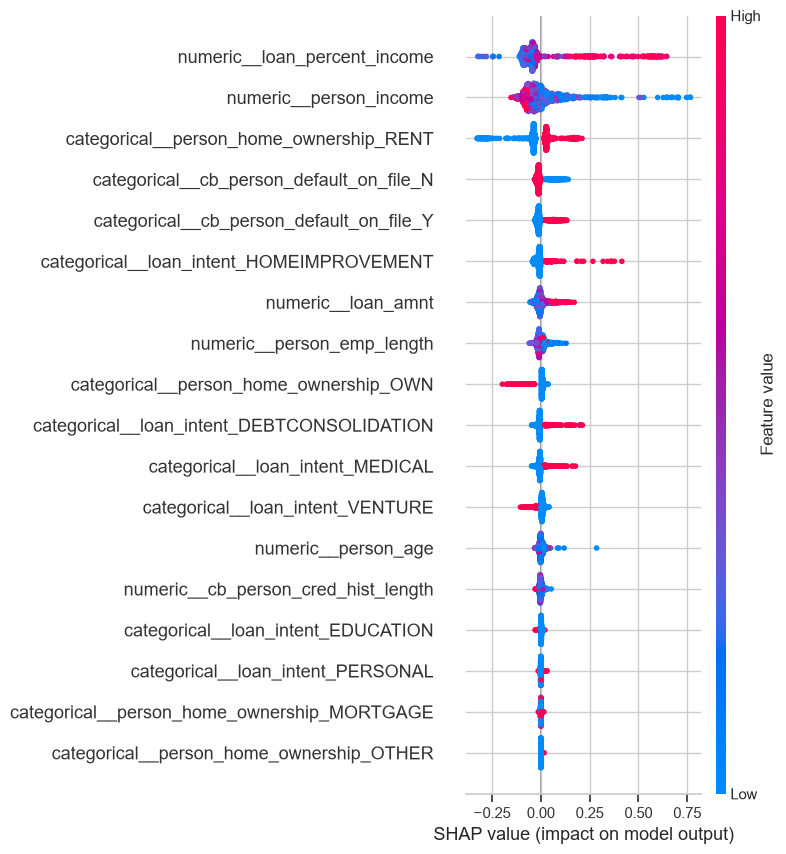

In [56]:
plt.figure()
shap.summary_plot(
    shap_default_values,
    shap_sample_processed,
    feature_names=feature_names,
    show=False,
    max_display=20,
)
plt.tight_layout()
plt.show()


In [57]:
with mlflow.start_run(run_name="random-forest-final-tuned-shap"):
    mlflow.set_tags({
        "model_type": "RandomForest",
        "analysis_type": "SHAP",
        "model_status": "final_tuned",
    })
    mlflow.log_table(shap_importance.head(20), "explainability/shap_importance.json")

print("SHAP analysis logged in MLflow.")


SHAP analysis logged in MLflow.
